In [1]:
import sys
RE_path = './RE_Solver/'
sys.path.insert(1, RE_path)

In [2]:
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
import importlib
import RE 
importlib.reload(RE)
from RE import *
from unit_conversion import *

# Deflection and Slowing Down Frequencies

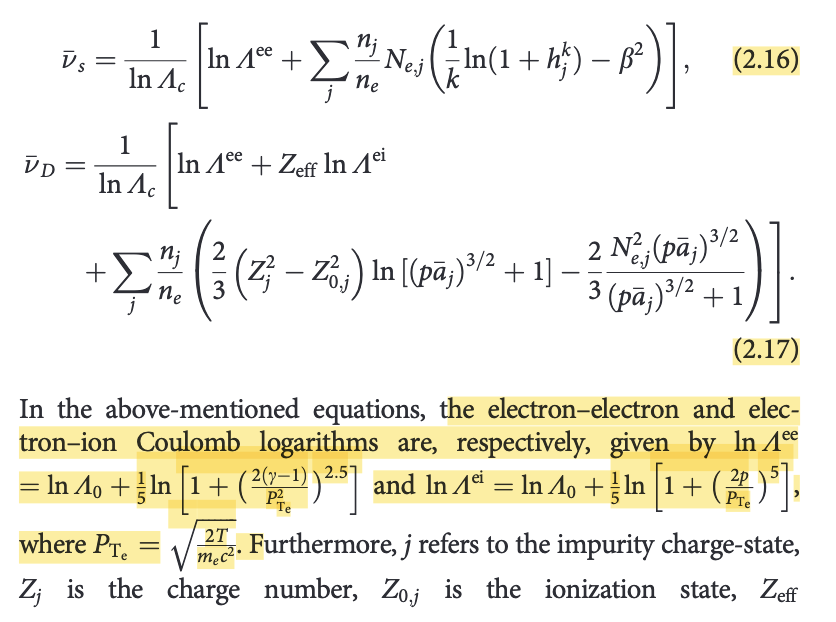

In [17]:
# functions

def get_nuD_nuS(p,Z,Z0,nj,T): # Presently Implemented for Neon
    
    # p = normalized momentum
    # Z = max. ionization
    # Z0 = ionization level
    # nj = density [per cubic m]
    # T = temperature [eV]
    
    # Constants
    ln_aBar_Ne = np.array([4.7064, 4.6097, 4.5028, 4.3858, 4.2638, 4.1266, 3.9568, 3.6810, 3.1777, 3.1278])
    ln_I_Ne = np.array([-8.2227, -8.0370, -7.8614, -7.6837, -7.4994, -7.2788, -6.9808, -6.5976, -5.8933, -5.8320])
    
    
    aBar_Ne = np.exp(ln_aBar_Ne)
    I_Ne = np.exp(ln_I_Ne)
    k = 5
    
    # Other Quantities
    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    Zeff = np.sum((Z0**2 * nj))/ne_free # Effective Ionization
    Ne = Z - Z0 # No. of bound electrons

    # Everything is a function of momentum p
    gamma = np.sqrt(1+p**2)
    beta = p**2 / (1 + p**2)
    
    # Coulomb Logs (also functions of p)
    PT = np.sqrt(2 * T / const.m_e / const.c**2) # Thermal velocity
    lnAc = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # RE-Thermal Coul. log
    lnA0 = 14.9 - 0.5 * np.log(ne_free/1e20) + np.log(T/1e3) # Thermal-Thermal Coul. Log
    lnAee = lnA0 + 1/5 * np.log(1 + (2*(gamma-1)/PT**2)**2.5)
    lnAei = lnA0 + 1/5 * np.log(1 + (2*p/PT)**5)
    # lnAee = lnAc + np.log(np.sqrt(gamma-1))
    # lnAei = lnAc + np.log(np.sqrt(2) * p)
    
    # Caluclate nuS and nuD (Bandaru + 2024)

    nuS = lnAee
    nuD = lnAee + Zeff * lnAei
    for j in range(1,Z.shape[0]):
        hj = p * np.sqrt(gamma-1) / I_Ne[Z0[j]]
        F1j = 1/k * np.log(1+hj**k) - beta**2
        pabar1p5 = (p*aBar_Ne[Z0[j]])**1.5
        nuS = nuS + (nj[j] / ne_free)  * Ne[j] * F1j
        nuD = nuD + (nj[j] / ne_free) * ( 
                      (2/3 * (Z[j]**2 - Z0[j]**2)) * np.log(pabar1p5+1)
                    - (2/3 * Ne[j]**2 * pabar1p5 / (pabar1p5+1))
                    )
#     # Hesslow + 2018    
#     nuS = lnAee
#     nuD = lnAee + Zeff * lnAei
#     for j in range(1,Z.shape[0]):
#         hj = p * np.sqrt(gamma-1) / I_Ne[Z0[j]]
#         nuS = nuS + (nj[j] / ne_free)  * Ne[j] * (np.log(hj) - beta**2)
#         nuD = nuD + (nj[j] / ne_free) * ( 
#                       (Z[j]**2 - Z0[j]**2) * np.log(p*aBar_Ne[Z0[j]])
#                     - 2/3 * Ne[j]**2
#                     )
        
    nuS = nuS / lnAc
    nuD = nuD / lnAc
    
    return nuD, nuS

##########

# Add the function for Argon
    

In [18]:
# Inputs
p = np.logspace(-1,2,1000)
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([0,1e20]); # Density
T = 10;

nuD, nuS = get_nuD_nuS(p,Z,Z0,nj,T)

(0.0, 10.0)

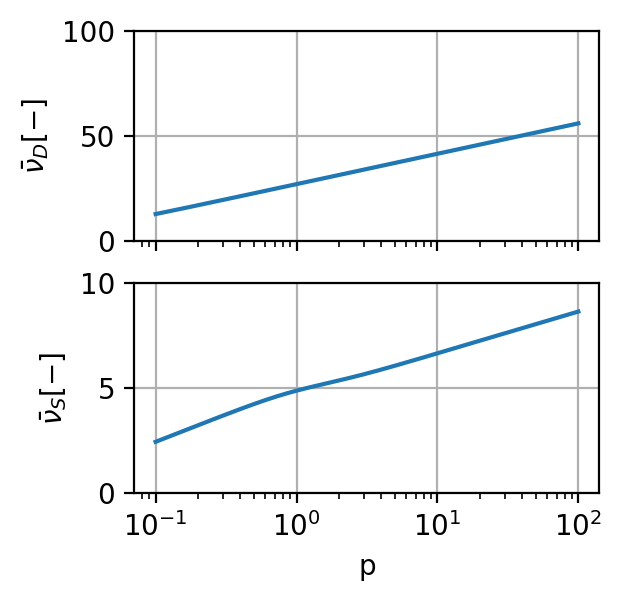

In [19]:
fig, axs = plt.subplots(2,1,dpi=200,sharex=True,figsize=(3,3))

axs[0].plot(p,nuD)
axs[1].plot(p,nuS)

axs[0].set_ylabel('$\\bar{\\nu}_D [-]$')
axs[1].set_ylabel('$\\bar{\\nu}_S [-]$')

for ii in range(axs.shape[0]):
    axs[ii].grid()
    axs[ii].set_xscale('log')
    
axs[-1].set_xlabel('p') 
axs[0].set_ylim([0,100])
axs[1].set_ylim([0,10])


# Compare (Hesslow + 2018 Fig. 1)

# data = np.loadtxt(RE_path + '/data/HesslowNenuD.csv',delimiter=',')
# axs[0].plot(data[:,0],data[:,1],'rx')

# data = np.loadtxt(RE_path + '/data/HesslowNenuS.csv',delimiter=',')
# axs[1].plot(data[:,0],data[:,1],'rx')
    

# Find pstar

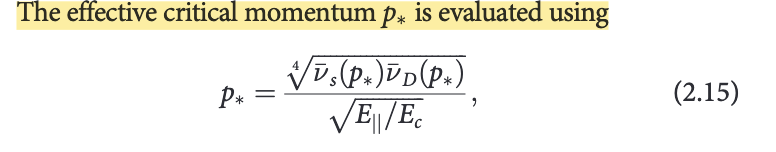

Here, $E_\parallel$ is the paralled electric field, $E_C$ is the Connor Hastie Field, $p_*$ is the (normalized) effective critical momentum

In [16]:
from scipy.optimize import fsolve

# Function to Solve
def fn(pstar,E_star,Z,Z0,nj,T):
    # T [eV]
    # Pstar = normalized momentum
    # Estar = Epar / E_CH (E_CH = Connor Hastie Critical Field)
    nuD, nuS = get_nuD_nuS(pstar,Z,Z0,nj,T)
    return pstar * (E_star)**(0.5) - (nuS * nuD)**(1/4)



pstar =  [2.72869228]


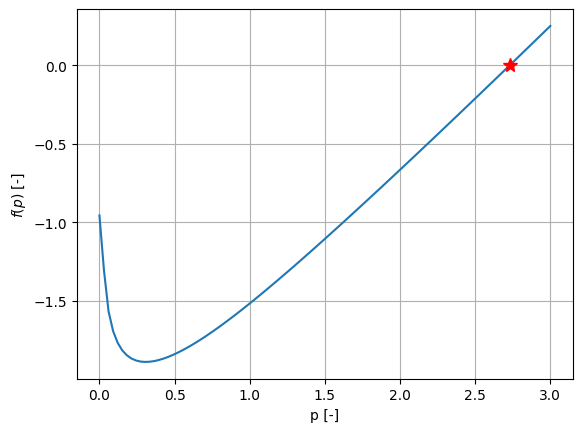

In [8]:
# Inputs
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;
E_star = 1

p = np.linspace(0,3,100)
y = fn(p,E_star,Z,Z0,nj,T)

plt.plot(p,y)
plt.xlabel('p [-]')
plt.ylabel('$f(p)$ [-]')
plt.grid()

# Solve the Equation to get pstar
out = fsolve(fn, 1, args=(E_star,Z,Z0,nj,T))
print('pstar = ', out)

plt.plot(out,0,'r*',markersize=10)

Text(0.5, 1.0, '$n_i, n_{Ne} = 1e+20, 1e+20,\\, T = 10.0 \\, eV$')

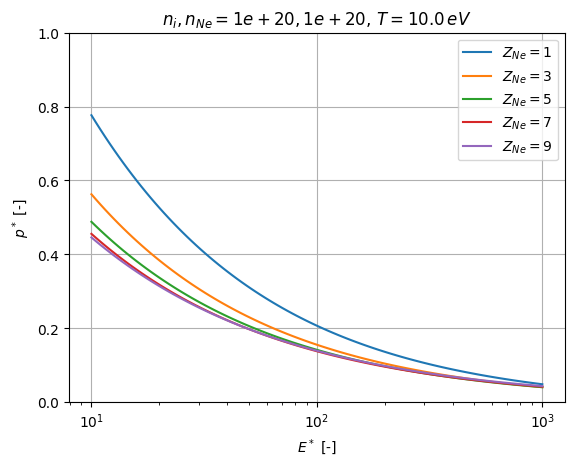

In [15]:
# Vary Estar

# Constants
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;

# Vary E_star
E_star = np.logspace(1,3,100)
pstar = np.zeros_like(E_star)

for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')


# Now Try different Ne ionizations

Z0 = np.array([1,3]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,5]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,7]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,9]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')





plt.xlabel('$E^*$ [-]')
plt.ylabel('$p^*$ [-]')
plt.grid()
plt.xscale('log')
plt.legend()
plt.ylim([0,1])
plt.title('$n_i, n_{Ne} = %1.3g, %1.3g,\, T = %1.1f \, eV$'%(nj[0],nj[1],T))
